# 03 - Model Experiments

**Goal:** compare the trained models, inspect the selected ones and relate the results to the PRD targets.

Everything here reads the artifacts created by the training scripts (`train_classical`, `train_clv`, `train_deep`, `clustering`, `explain`), so run those first.

| Task | Target |
|---|---|
| Churn classification | ROC-AUC >= 0.80 and recall >= 0.70 |
| Customer lifetime value | R-squared >= 0.60 |

In [1]:
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

# Work from the project root no matter where Jupyter was started.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.utils.config import get_config_value, resolve_path

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})
print("Project folder:", ROOT)

import json

import joblib
from sklearn.calibration import calibration_curve
from sklearn.metrics import ConfusionMatrixDisplay, auc, precision_recall_curve, roc_curve

from src.models.data_prep import prepare_data
from src.models.evaluate import regression_metrics

ART = resolve_path(get_config_value("paths.artifacts_dir", "models_artifacts"))
TARGETS = get_config_value("training.targets", {"roc_auc": 0.80, "recall": 0.70, "clv_r2": 0.60})

Project folder: e:\customer-behavior-prediction


## 1. Churn models compared

In [2]:
churn = pd.read_csv(ART / "churn_model_comparison.csv")
deep_path = ART / "deep_model_comparison.csv"
if deep_path.exists():
    deep = pd.read_csv(deep_path)
    churn = pd.concat([churn.assign(family="classical"), deep.assign(family="deep learning")], ignore_index=True)
else:
    churn = churn.assign(family="classical")

churn = churn.sort_values("val_roc_auc", ascending=False).reset_index(drop=True)
churn["meets_targets"] = (churn["test_roc_auc"] >= TARGETS["roc_auc"]) & (churn["test_recall"] >= TARGETS["recall"])
display(churn[["model", "family", "val_roc_auc", "test_roc_auc", "test_recall", "test_precision", "test_f1", "test_accuracy", "meets_targets"]])

,model,family,val_roc_auc,test_roc_auc,test_recall,test_precision,test_f1,test_accuracy,meets_targets
0,lstm,deep learning,0.816,0.804,0.828,0.741,0.782,0.738,True
1,xgboost,classical,0.814,0.813,0.875,0.755,0.811,0.768,True
2,lightgbm,classical,0.814,0.815,0.879,0.739,0.803,0.756,True
3,logistic_regression,classical,0.811,0.802,0.723,0.788,0.754,0.733,True
4,ann,deep learning,0.811,0.801,0.795,0.766,0.780,0.746,True
5,random_forest,classical,0.811,0.806,0.857,0.759,0.805,0.765,True
6,decision_tree,classical,0.779,0.782,0.806,0.754,0.779,0.741,False
7,knn,classical,0.775,0.772,0.815,0.737,0.774,0.730,False


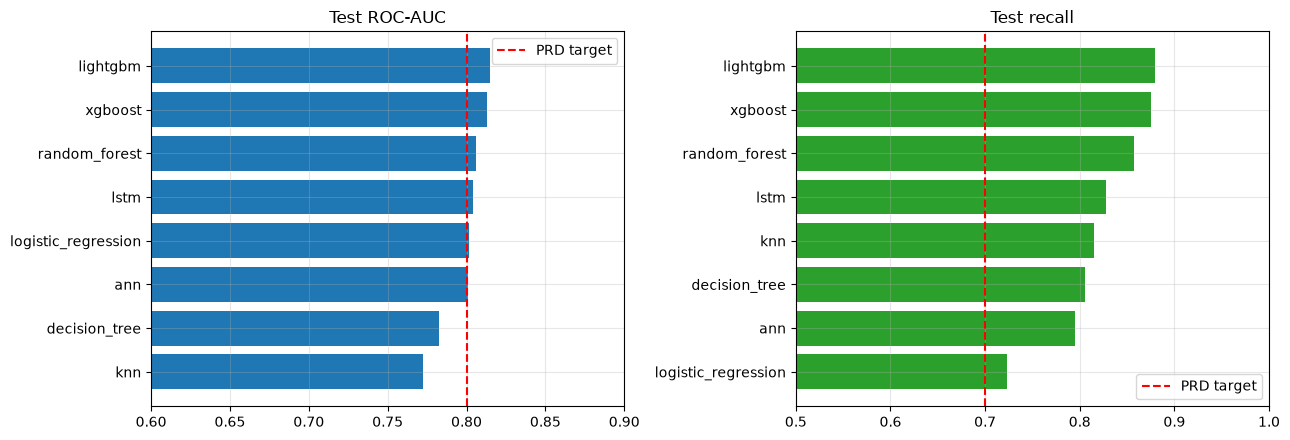

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = churn.sort_values("test_roc_auc")
axes[0].barh(order["model"], order["test_roc_auc"], color="tab:blue")
axes[0].axvline(TARGETS["roc_auc"], color="red", linestyle="--", label="PRD target")
axes[0].set(title="Test ROC-AUC", xlim=(0.6, 0.9)); axes[0].legend()

order = churn.sort_values("test_recall")
axes[1].barh(order["model"], order["test_recall"], color="tab:green")
axes[1].axvline(TARGETS["recall"], color="red", linestyle="--", label="PRD target")
axes[1].set(title="Test recall", xlim=(0.5, 1.0)); axes[1].legend()
plt.tight_layout()
plt.show()

Models are **ranked on the validation set** and the test set is used once for the final numbers, so the test scores are an honest estimate.

## 2. The selected churn model in detail

In [4]:
meta = json.loads((ART / "churn_metadata.json").read_text())
name = get_config_value("api.model_name", meta.get("best_model_by_val_auc", "xgboost"))
threshold = meta["thresholds"][name]
model = joblib.load(ART / f"churn_{name}.joblib")

data = prepare_data()
X_val, y_val = data.X("val"), data.y("val")
X_test, y_test = data.X("test"), data.y("test")
val_proba = model.predict_proba(X_val)[:, 1]
test_proba = model.predict_proba(X_test)[:, 1]
print(f"Model: {name} | decision threshold chosen on validation data: {threshold:.3f}")

2026-10-22 18:09:30 | INFO     | src.models.data_prep | train  3,682 customers | churn rate 56.7%
2026-10-22 18:09:30 | INFO     | src.models.data_prep | val      790 customers | churn rate 56.7%
2026-10-22 18:09:30 | INFO     | src.models.data_prep | test     790 customers | churn rate 56.7%
2026-10-22 18:09:30 | INFO     | src.models.data_prep | Using 29 features
Model: xgboost | decision threshold chosen on validation data: 0.446


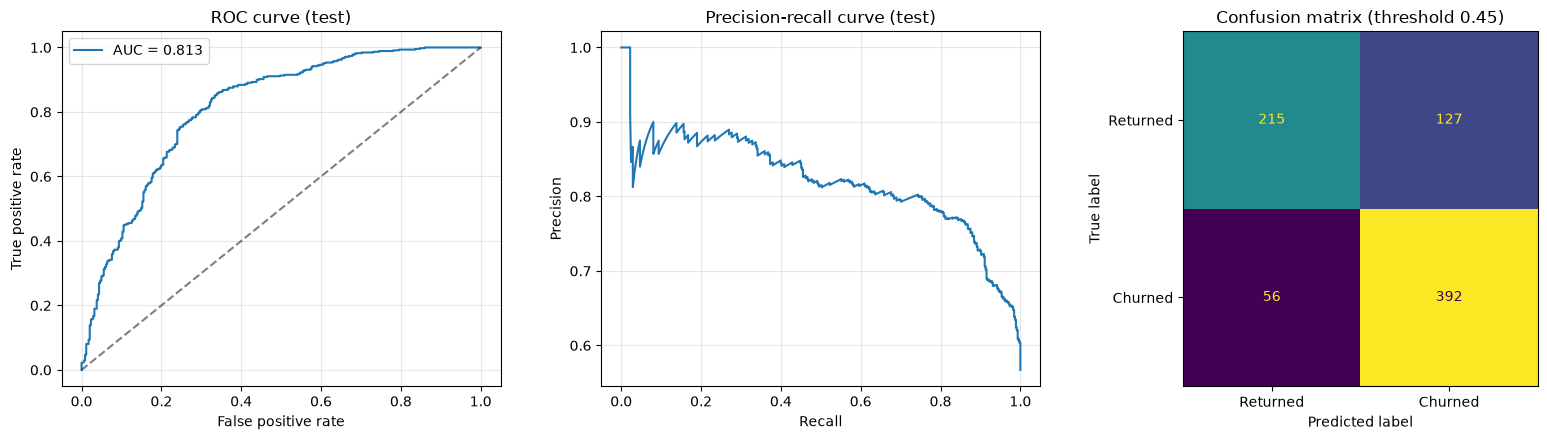

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[0].plot(fpr, tpr, label=f"AUC = {auc(fpr, tpr):.3f}")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set(title="ROC curve (test)", xlabel="False positive rate", ylabel="True positive rate"); axes[0].legend()

precision, recall, _ = precision_recall_curve(y_test, test_proba)
axes[1].plot(recall, precision)
axes[1].set(title="Precision-recall curve (test)", xlabel="Recall", ylabel="Precision")

ConfusionMatrixDisplay.from_predictions(y_test, test_proba >= threshold, display_labels=["Returned", "Churned"], ax=axes[2], colorbar=False)
axes[2].set(title=f"Confusion matrix (threshold {threshold:.2f})"); axes[2].grid(False)
plt.tight_layout()
plt.show()

### Choosing the threshold

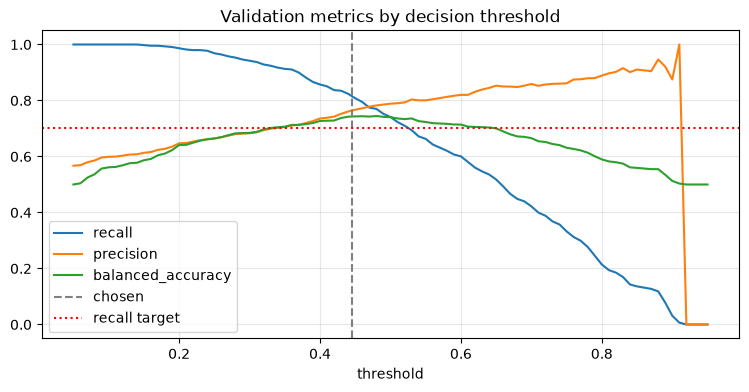

In [6]:
thresholds = np.linspace(0.05, 0.95, 91)
rows = []
for t in thresholds:
    predicted = val_proba >= t
    tp = int(((predicted) & (y_val == 1)).sum()); fn = int(((~predicted) & (y_val == 1)).sum())
    fp = int(((predicted) & (y_val == 0)).sum()); tn = int(((~predicted) & (y_val == 0)).sum())
    recall_ = tp / max(tp + fn, 1); specificity = tn / max(tn + fp, 1)
    rows.append({"threshold": t, "recall": recall_, "precision": tp / max(tp + fp, 1), "balanced_accuracy": (recall_ + specificity) / 2})
sweep = pd.DataFrame(rows).set_index("threshold")

sweep.plot(figsize=(9, 4))
plt.axvline(threshold, color="grey", linestyle="--", label="chosen")
plt.axhline(TARGETS["recall"], color="red", linestyle=":", label="recall target")
plt.title("Validation metrics by decision threshold"); plt.legend()
plt.show()

Churners are the **majority** class (about 57%), so plain F1 would reward flagging almost everyone. The threshold is therefore the one with the best *balanced accuracy* among those that keep recall above the target.

### Are the probabilities trustworthy?

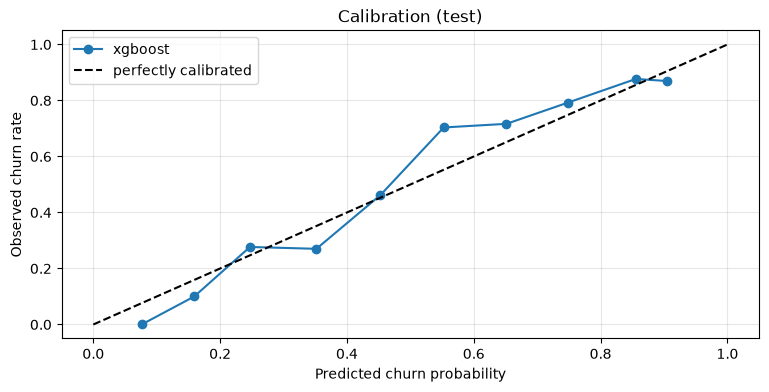

In [7]:
fraction_positive, mean_predicted = calibration_curve(y_test, test_proba, n_bins=10)
plt.plot(mean_predicted, fraction_positive, marker="o", label=name)
plt.plot([0, 1], [0, 1], "k--", label="perfectly calibrated")
plt.title("Calibration (test)"); plt.xlabel("Predicted churn probability"); plt.ylabel("Observed churn rate"); plt.legend()
plt.show()

## 3. Customer lifetime value

In [8]:
clv = pd.read_csv(ART / "clv_model_comparison.csv")
clv["meets_target"] = clv["test_r2"] >= TARGETS["clv_r2"]
display(clv[["model", "val_r2_log", "test_r2_log", "test_r2", "test_mae", "test_rmse", "test_spearman", "meets_target"]])
print(f"PRD target: raw R-squared >= {TARGETS['clv_r2']}. Best raw test R-squared: {clv['test_r2'].max():.3f}")

,model,val_r2_log,test_r2_log,test_r2,test_mae,test_rmse,test_spearman,meets_target
0,xgboost,0.385,0.356,0.384,310.346,881.578,0.575,False
1,random_forest,0.379,0.360,0.541,298.514,761.512,0.578,False
2,lightgbm,0.373,0.347,0.307,317.943,935.293,0.568,False
3,ridge,0.369,0.341,0.206,334.552,"1,001.430",0.572,False


PRD target: raw R-squared >= 0.6. Best raw test R-squared: 0.541


xgboost {'mae': 310.346, 'rmse': 881.578, 'r2': 0.384}


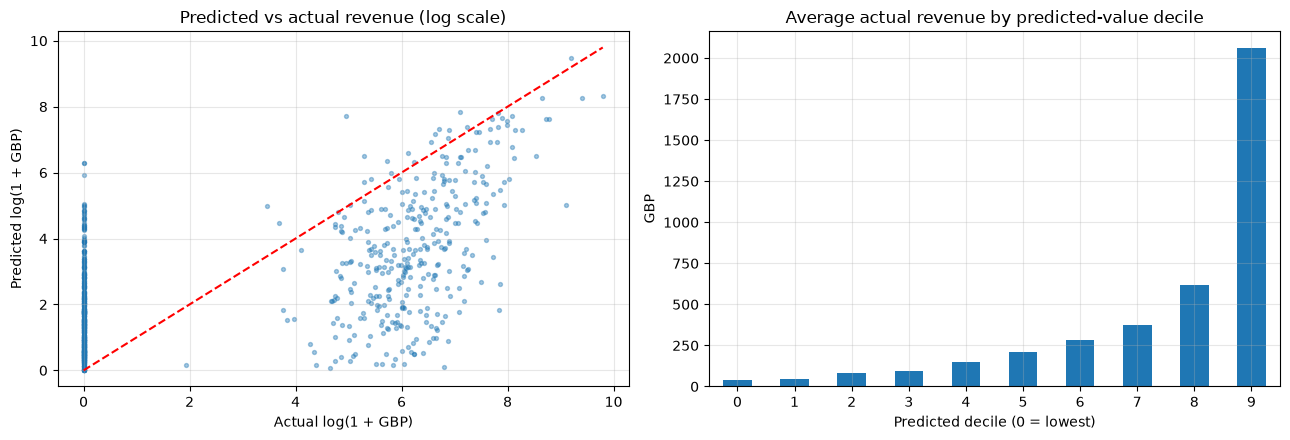

In [9]:
clv_meta = json.loads((ART / "clv_metadata.json").read_text())
clv_name = clv_meta["best_model_by_val_r2_log"]
clv_model = joblib.load(ART / f"clv_{clv_name}.joblib")

actual = data.y("test", "future_revenue").to_numpy()
predicted = np.clip(clv_model.predict(X_test), 0, None)
print(clv_name, {key: round(value, 3) for key, value in regression_metrics(actual, predicted).items()})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(np.log1p(actual), np.log1p(predicted), s=8, alpha=0.4)
limit = max(np.log1p(actual).max(), np.log1p(predicted).max())
axes[0].plot([0, limit], [0, limit], "r--")
axes[0].set(title="Predicted vs actual revenue (log scale)", xlabel="Actual log(1 + GBP)", ylabel="Predicted log(1 + GBP)")

deciles = pd.qcut(pd.Series(predicted).rank(method="first"), 10, labels=False)
pd.DataFrame({"actual": actual, "decile": deciles}).groupby("decile")["actual"].mean().plot.bar(ax=axes[1], color="tab:blue", rot=0)
axes[1].set(title="Average actual revenue by predicted-value decile", xlabel="Predicted decile (0 = lowest)", ylabel="GBP")
plt.tight_layout()
plt.show()

The raw R-squared target is **not reached**. Most customers spend nothing and a few spend a great deal, which is hard to predict from purchase history alone. The decile chart shows that the model still **ranks customers well**: those predicted to be most valuable do spend the most, which is what retention prioritisation needs.

## 4. Customer segments

,cluster,segment,customers,share_pct,recency_days,frequency,monetary_total,monetary_avg,avg_basket_size,tenure_days,interpurchase_mean_days,return_rate,discount_line_share,seasonal_order_share,purchase_frequency_trend,category_entropy,churn_rate,avg_future_revenue
0,0,Champions,1199,22.786,69.675,15.512,"8,514.078",537.771,331.005,562.349,60.254,0.024,0.088,0.246,-0.035,0.776,0.234,"1,621.491"
1,1,New & Promising,842,16.002,91.132,2.232,734.038,356.586,220.254,136.638,23.535,0.014,0.050,0.002,0.039,0.655,0.514,390.830
2,2,Discount Bulk Buyers,272,5.169,236.273,3.956,"3,116.505",828.096,"1,013.419",413.049,60.643,0.042,0.747,0.212,-0.003,0.262,0.721,497.992
3,3,At Risk,1682,31.965,207.691,4.076,980.943,261.610,148.964,500.315,129.432,0.019,0.031,0.310,-0.023,0.722,0.607,175.249
4,4,Lost Customers,736,13.987,443.397,1.238,235.592,205.028,116.367,453.087,7.461,0.037,0.026,0.037,-0.003,0.497,0.880,44.912
5,5,Seasonal Shoppers,531,10.091,353.988,1.294,410.346,323.919,194.672,358.679,3.404,0.024,0.024,0.997,-0.033,0.656,0.765,110.500


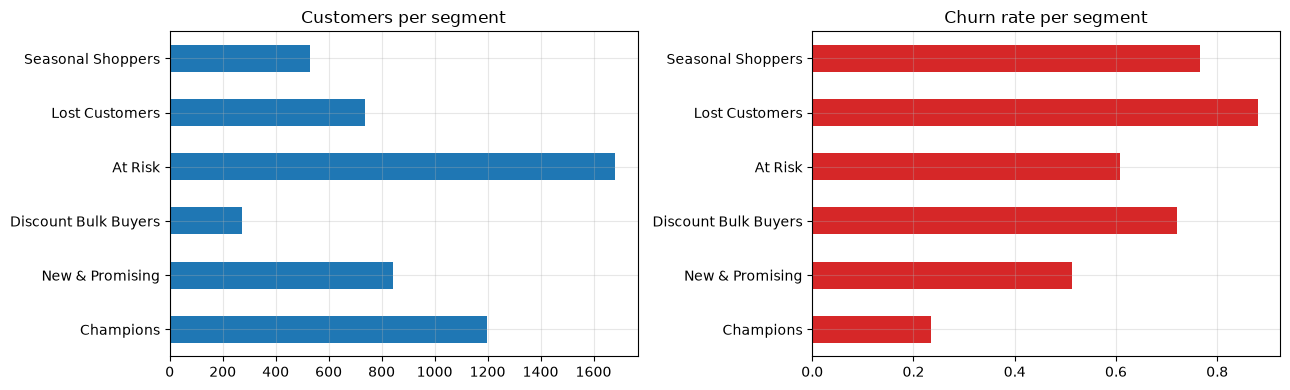

In [10]:
profiles = pd.read_csv(ART / "segment_profiles.csv")
display(profiles)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
profiles.set_index("segment")["customers"].plot.barh(ax=axes[0], color="tab:blue")
axes[0].set(title="Customers per segment", ylabel="")
if "churn_rate" in profiles:
    profiles.set_index("segment")["churn_rate"].plot.barh(ax=axes[1], color="tab:red")
    axes[1].set(title="Churn rate per segment", ylabel="")
plt.tight_layout()
plt.show()

## 5. Explainability plots

6 figures found in docs/figures
hierarchical_dendrogram.png


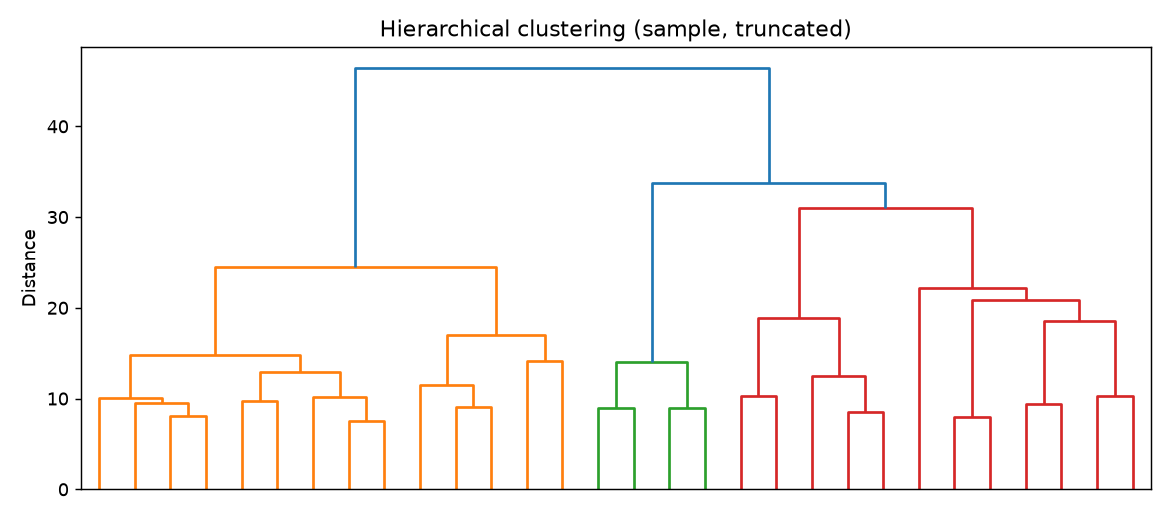

kmeans_k_selection.png


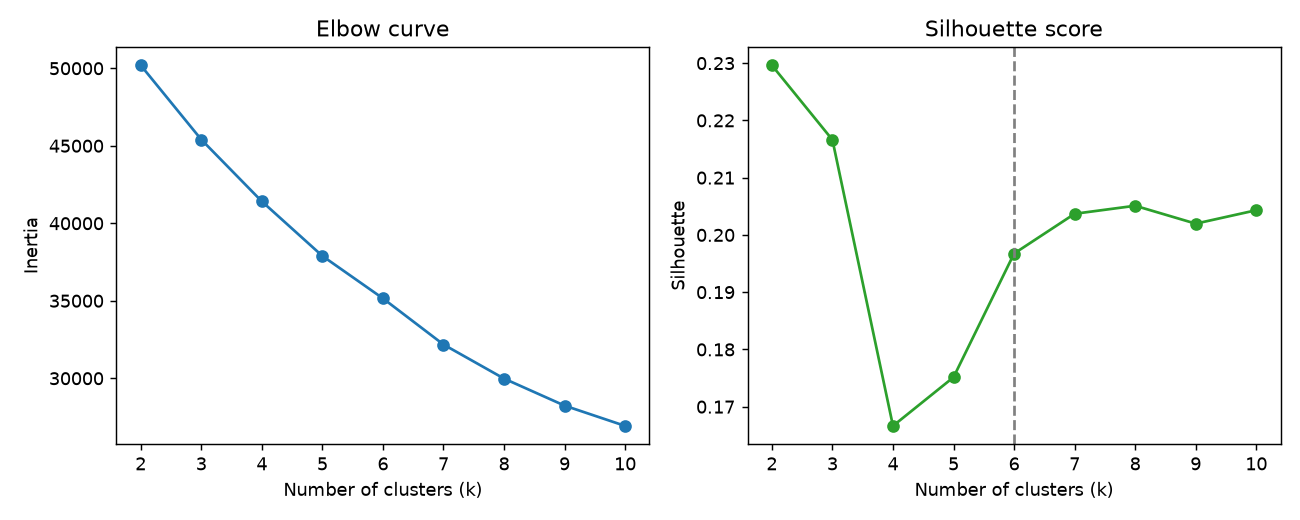

partial_dependence.png


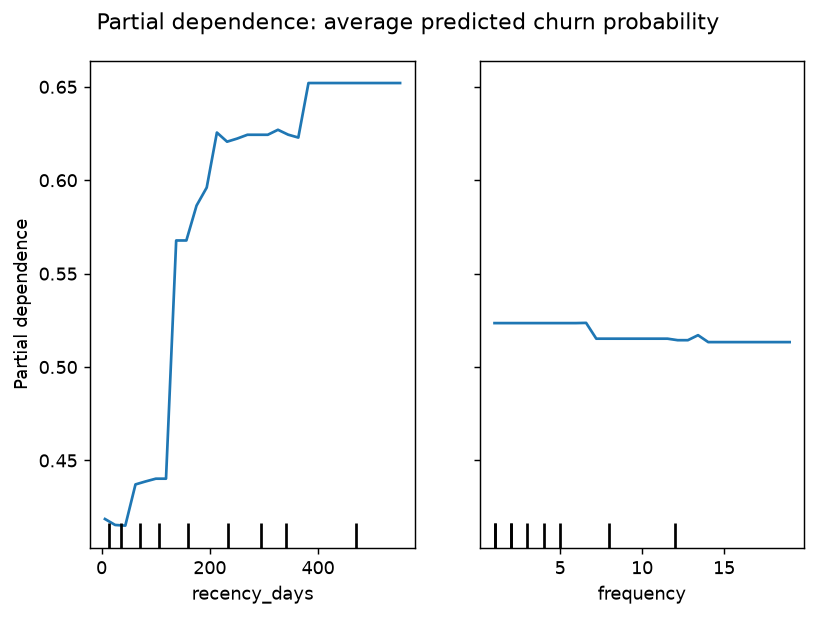

segments_pca.png


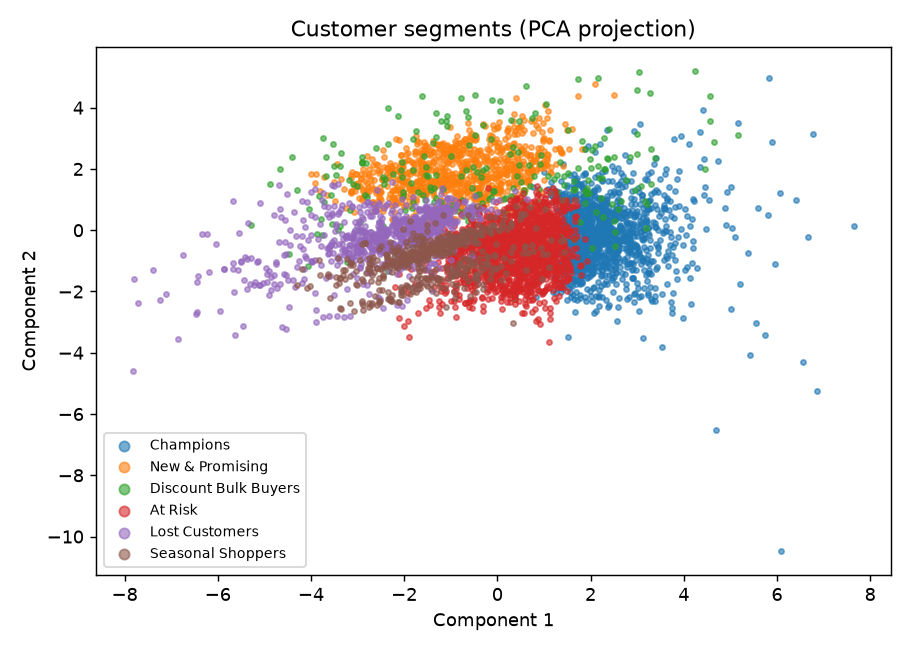

shap_importance.png


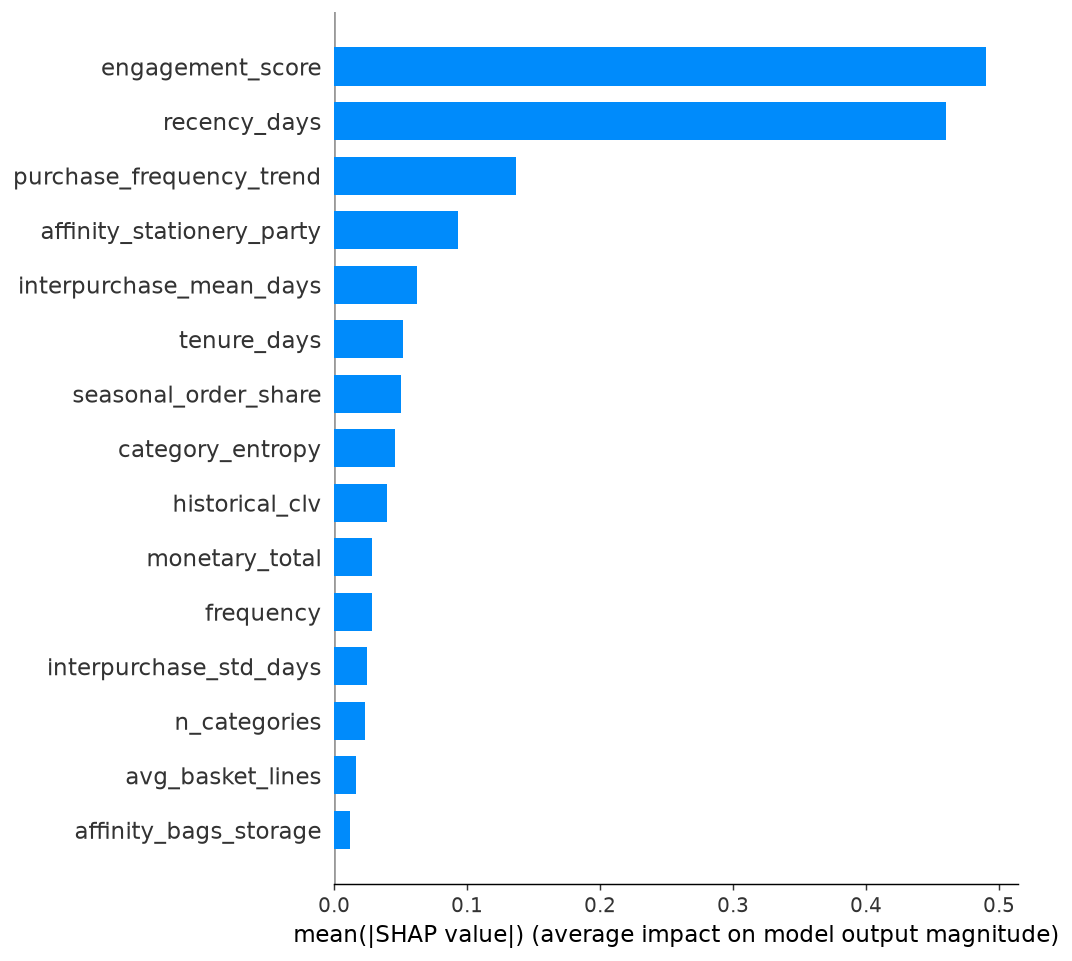

shap_summary.png


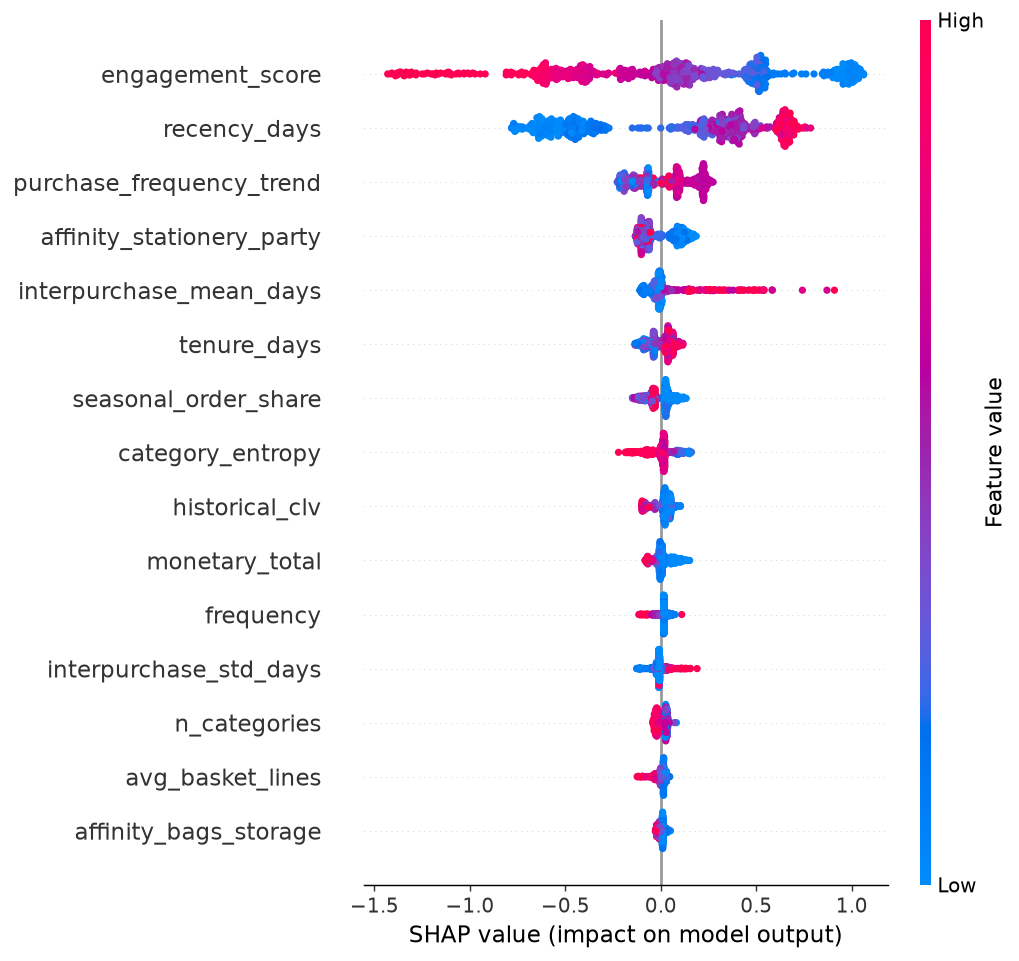

In [11]:
from IPython.display import Image

figures = sorted((ROOT / "docs" / "figures").glob("*.png"))
print(f"{len(figures)} figures found in docs/figures")
for figure in figures[:6]:
    print(figure.name)
    display(Image(filename=str(figure), width=700))

## 6. Conclusions

- **Churn:** several model families clear both PRD targets. XGBoost was selected on validation ROC-AUC; LightGBM, random forest and the neural networks are within about 0.01 AUC, so the choice between them is not critical.
- **High recall by design:** the threshold keeps recall well above 0.70 so that few churners are missed, at the cost of some false alarms.
- **CLV:** the raw R-squared target is not met, but ranking quality is useful. A two-stage model (will the customer buy? then how much?) is the most promising next step.
- **Segments:** six interpretable groups give the business simple labels to act on.
- **Not yet done:** customer country as a feature, automated retraining and drift monitoring.